<div style="
    max-width: 850px;
    margin: auto;
    background: #ffd6e0;
    padding: 35px;
    border-radius: 20px;
    color: #000000;
    font-family: 'Segoe UI', sans-serif;
    line-height: 1.9;
    box-shadow: 0px 4px 20px rgba(0, 0, 0, 0.15);
    border: 1px solid #ffffff;
">

<h1 style="
    text-align:center;
    color:#000000;
    margin-bottom:10px;
    font-size: 32px;
">
📩 Spam Message Detection System
</h1>

<h3 style="
    text-align:center;
    color:#000000;
    font-weight:normal;
    font-size: 20px;
">
NLP Project
</h3>

<hr style="
    border:1px solid #ffffff;
    margin:25px 0;
">

<p style="
    font-size:18px;
    color:#000000;
    text-align:justify;
">

This project aims to build an intelligent <b>Spam Message Detection System</b> using 
<b>Natural Language Processing (NLP)</b> and multiple <b>Machine Learning Algorithms</b>.  

The dataset undergoes cleaning, preprocessing, feature extraction using 
<b>TF-IDF Vectorization</b>, and model training to classify messages as 
<b>Spam</b> or <b>Ham</b>.

</p>

<br>

<h2 style="color:#000000; font-size: 24px;">🤖 Implemented Algorithms</h2>

<ul style="font-size:17px; padding-left:20px; color:#000000;">
<li>Multinomial Naive Bayes</li>
<li>Bernoulli Naive Bayes</li>
<li>Logistic Regression</li>
<li>Perceptron</li>
<li>Ensemble Learning</li>
</ul>

<br>

<h2 style="color:#000000; font-size: 24px;">🔧 Project Workflow</h2>

<ul style="font-size:17px; padding-left:20px; color:#000000;">
<li>Data Loading & Cleaning</li>
<li>Exploratory Data Analysis (EDA)</li>
<li>Text Preprocessing</li>
<li>TF-IDF Feature Extraction</li>
<li>Model Training & Evaluation</li>
<li>Models Comparison</li>
<li>Saving Trained Models</li>
</ul>

<br>

<div style="
    background-color:#ffffff;
    padding:14px;
    border-radius:12px;
    text-align:center;
    font-size:16px;
    color:#000000;
    margin-top:15px;
    border:1px solid #ffffff;
">

✨ The project focuses on comparing multiple ML algorithms to achieve the best spam classification performance.

</div>

</div>

***Import Libraries***



In [1]:
import pandas as pd
import numpy as np
import re
import string
import math
import random
import matplotlib.pyplot as plt
from collections import Counter
import pickle

 
random.seed(42)
np.random.seed(42)

***Load and Prepare Dataset***

In [2]:
 
df = pd.read_csv("spam.csv", encoding='latin-1')

In [3]:
df = df[['v1', 'v2']]
df.columns = ['label', 'text']

In [4]:
df['label'] = df['label'].map({'ham': 0, 'spam': 1})

In [5]:
df.drop_duplicates(inplace=True)
df.dropna(inplace=True)

In [6]:
print("Shape:", df.shape)
print(df['label'].value_counts())

Shape: (5169, 2)
label
0    4516
1     653
Name: count, dtype: int64


***Text Cleaning and Preprocessing***


In [7]:
print("Dataset Shape:", df.shape)

Dataset Shape: (5169, 2)


In [8]:
print("\nClass Distribution:")
print(df['label'].value_counts())


Class Distribution:
label
0    4516
1     653
Name: count, dtype: int64


In [9]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
label    0
text     0
dtype: int64


In [10]:
print("\nSample Data:")
display(df.head())


Sample Data:


,label,text
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


***Exploratory Data Analysis (EDA)***


===== Quick EDA on Raw Spam Dataset =====

Dataset shape: (5169, 2)
Missing values: 0
Duplicates: 0

Class distribution:
  Ham : 4516 (87.4%)
  Spam: 653 (12.6%)

Message length (characters):
  Ham  - mean: 70.5, std: 56.4
  Spam - mean: 137.9, std: 30.1

--- Example Ham message ---
Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

--- Example Spam message ---
Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's


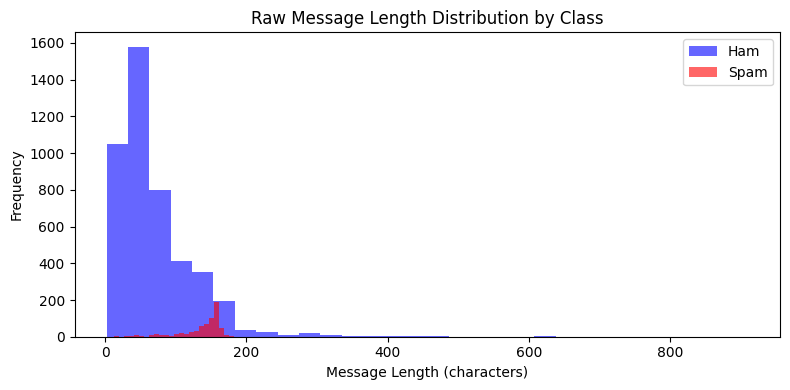


Lightweight EDA complete. Ready for preprocessing.


In [11]:
print("\n===== Quick EDA on Raw Spam Dataset =====\n")

df_raw = df[['label', 'text']].copy()

print(f"Dataset shape: {df_raw.shape}")
print(f"Missing values: {df_raw.isnull().sum().sum()}")
print(f"Duplicates: {df_raw.duplicated().sum()}")

 
ham_count = (df_raw['label'] == 0).sum()
spam_count = (df_raw['label'] == 1).sum()
print(f"\nClass distribution:")
print(f"  Ham : {ham_count} ({ham_count/len(df_raw)*100:.1f}%)")
print(f"  Spam: {spam_count} ({spam_count/len(df_raw)*100:.1f}%)")

 
df_raw['raw_length'] = df_raw['text'].astype(str).apply(len)
print(f"\nMessage length (characters):")
print(f"  Ham  - mean: {df_raw[df_raw['label']==0]['raw_length'].mean():.1f}, std: {df_raw[df_raw['label']==0]['raw_length'].std():.1f}")
print(f"  Spam - mean: {df_raw[df_raw['label']==1]['raw_length'].mean():.1f}, std: {df_raw[df_raw['label']==1]['raw_length'].std():.1f}")

 
print("\n--- Example Ham message ---")
print(df_raw[df_raw['label']==0]['text'].iloc[0])
print("\n--- Example Spam message ---")
print(df_raw[df_raw['label']==1]['text'].iloc[0])

 
import matplotlib.pyplot as plt
plt.figure(figsize=(8,4))
plt.hist(df_raw[df_raw['label']==0]['raw_length'], bins=30, alpha=0.6, label='Ham', color='blue')
plt.hist(df_raw[df_raw['label']==1]['raw_length'], bins=30, alpha=0.6, label='Spam', color='red')
plt.xlabel('Message Length (characters)')
plt.ylabel('Frequency')
plt.title('Raw Message Length Distribution by Class')
plt.legend()
plt.tight_layout()
plt.show()

print("\nLightweight EDA complete. Ready for preprocessing.")

In [12]:
 
stopwords = set({
    "i", "me", "my", "myself", "we", "our", "ours", "ourselves", "you", "your", "yours",
    "he", "him", "his", "himself", "she", "her", "hers", "herself", "it", "its", "itself",
    "they", "them", "their", "theirs", "themselves", "a", "an", "and", "if", "or", "but",
    "the", "this", "that", "these", "those", "so", "such", "is", "am", "are", "was", "were",
    "be", "being", "been", "has", "have", "having", "do", "does", "doing", "will", "would",
    "can", "could", "should", "must", "to", "of", "for", "with", "without", "on", "at",
    "by", "in", "out", "up", "down", "off", "over", "under", "again", "further", "then",
    "once", "here", "there", "all", "any", "both", "each", "few", "more", "most", "other",
    "some", "such", "no", "nor", "not", "only", "own", "same", "than", "that", "then",
    "very", "just", "but", "don", "now", "then", "than", "into", "via", "etc"
})



In [13]:
def simple_stem(word):
     
    if len(word) < 4:
        return word
    for suf in ["ing", "ly", "ed", "es", "s", "ment", "tion"]:
        if word.endswith(suf):
            word = word[:-len(suf)]
            break
     
    if len(word) > 2 and word[-1] == word[-2]:
        word = word[:-1]
    return word

In [14]:
def generate_bigrams(tokens):
     
    bigrams = []
    for i in range(len(tokens)-1):
        bigrams.append(tokens[i] + "_" + tokens[i+1])
    return tokens + bigrams

In [15]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\S+|https\S+', '', text)
    text = re.sub(r'\d+', '', text)
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = re.sub(r'\s+', ' ', text).strip()
    
    tokens = text.split()
    
    tokens = [simple_stem(word) for word in tokens if word not in stopwords and len(word) >= 3]
    tokens = generate_bigrams(tokens)
    return tokens


In [16]:
df['tokens'] = df['text'].apply(clean_text)
print("clean text done")

clean text done


In [17]:
MAX_FEATURES = 4000
word_freq = Counter()
for tokens in df['tokens']:
    word_freq.update(set(tokens))    

top_words = [word for word, _ in word_freq.most_common(MAX_FEATURES)]
vocab = {word: idx for idx, word in enumerate(top_words)}
print(f"Dictionary size: {len(vocab)}")

Dictionary size: 4000


****TF-IDF Computation****

In [18]:
def compute_idf(texts_tokens, vocab):
    N = len(texts_tokens)
    doc_count = [0] * len(vocab)
    for tokens in texts_tokens:
        seen = set(tokens)
        for word in seen:
            if word in vocab:
                doc_count[vocab[word]] += 1
    idf = [0] * len(vocab)
    for i in range(len(vocab)):
         
        idf[i] = math.log((N + 1) / (doc_count[i] + 1)) + 1
    return idf



In [19]:
def compute_tfidf(tokens, vocab, idf):
     
    vec = [0] * len(vocab)
    for word in tokens:
        if word in vocab:
            vec[vocab[word]] += 1
     
    for i in range(len(vec)):
        vec[i] = vec[i] * idf[i]
     
    norm = math.sqrt(sum(x*x for x in vec))
    if norm > 0:
        vec = [x / norm for x in vec]
    return vec

In [20]:
all_tokens = df['tokens'].tolist()
 
idf = compute_idf(all_tokens, vocab)
 
X = [compute_tfidf(tokens, vocab, idf) for tokens in all_tokens]
y = df['label'].tolist()

X = np.array(X)
y = np.array(y)
print("X shape:", X.shape)

X shape: (5169, 4000)


****Manual Train-Test Split****

In [21]:
def train_test_split_manual(X, y, test_size=0.2, random_state=42):
    random.seed(random_state)
    indices = list(range(len(X)))
    random.shuffle(indices)
    split = int(len(X) * (1 - test_size))
    train_idx = indices[:split]
    test_idx = indices[split:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]


In [22]:
def compute_metrics(y_true, y_pred):
    tp = sum((yt==1 and yp==1) for yt,yp in zip(y_true,y_pred))
    tn = sum((yt==0 and yp==0) for yt,yp in zip(y_true,y_pred))
    fp = sum((yt==0 and yp==1) for yt,yp in zip(y_true,y_pred))
    fn = sum((yt==1 and yp==0) for yt,yp in zip(y_true,y_pred))
    acc = (tp+tn)/(tp+tn+fp+fn) if (tp+tn+fp+fn)>0 else 0
    prec = tp/(tp+fp) if (tp+fp)>0 else 0
    rec = tp/(tp+fn) if (tp+fn)>0 else 0
    f1 = 2*prec*rec/(prec+rec) if (prec+rec)>0 else 0
    return acc, prec, rec, f1, tp, tn, fp, fn

In [23]:
def print_confusion_matrix(tp, tn, fp, fn):
    print("Confusion Matrix:")
    print("          Predicted")
    print("          Ham   Spam")
    print(f"Actual Ham  {tn:3d}   {fp:3d}")
    print(f"       Spam {fn:3d}   {tp:3d}")

In [24]:
def print_full_report(y_true, y_pred, target_names):
    acc, prec, rec, f1, tp, tn, fp, fn = compute_metrics(y_true, y_pred)
     
    prec_ham = tn/(tn+fp) if (tn+fp)>0 else 0
    rec_ham = tn/(tn+fn) if (tn+fn)>0 else 0
    f1_ham = 2*prec_ham*rec_ham/(prec_ham+rec_ham) if (prec_ham+rec_ham)>0 else 0
    
    prec_spam = tp/(tp+fp) if (tp+fp)>0 else 0
    rec_spam = tp/(tp+fn) if (tp+fn)>0 else 0
    f1_spam = 2*prec_spam*rec_spam/(prec_spam+rec_spam) if (prec_spam+rec_spam)>0 else 0
    
    print(f"{'':>12}{'precision':>10}{'recall':>10}{'f1-score':>10}{'support':>10}")
    print(f"{target_names[0]:>12}{prec_ham:>10.3f}{rec_ham:>10.3f}{f1_ham:>10.3f}{tn+fp:>10}")
    print(f"{target_names[1]:>12}{prec_spam:>10.3f}{rec_spam:>10.3f}{f1_spam:>10.3f}{tp+fn:>10}")
    print(f"\nAccuracy: {(tp+tn)/(tp+tn+fp+fn):.4f}")
    print_confusion_matrix(tp, tn, fp, fn)

****Random Over Sampling****


In [25]:
def random_over_sampling(X, y, random_state=42):
    
    random.seed(random_state)
    np.random.seed(random_state)
    X = np.array(X)
    y = np.array(y)
    minority_idx = np.where(y == 1)[0]
    majority_idx = np.where(y == 0)[0]
    n_to_add = len(majority_idx) - len(minority_idx)
    if n_to_add <= 0:
        return X, y
     
    sampled_idx = np.random.choice(minority_idx, size=n_to_add, replace=True)
    X_bal = np.vstack([X, X[sampled_idx]])
    y_bal = np.hstack([y, y[sampled_idx]])
    return X_bal, y_bal

In [26]:
X_train, X_test, y_train, y_test = train_test_split_manual(X, y, test_size=0.2)

print("Before Random Over-Sampling - Train size:", len(X_train), "Spam:", sum(y_train))
X_train_bal, y_train_bal = random_over_sampling(X_train, y_train)
print("After  Random Over-Sampling - Train size:", len(X_train_bal), "Spam:", sum(y_train_bal))

Before Random Over-Sampling - Train size: 4135 Spam: 506
After  Random Over-Sampling - Train size: 7258 Spam: 3629


****EDA on TF-IDF data after Oversampling****


===== EDA on TF-IDF data after Oversampling =====

Training set size BEFORE oversampling: 4135 (ham: 3629, spam: 506)
Training set size AFTER oversampling:  7258 (ham: 3629, spam: 3629)
New balance ratio (ham/spam): 1.00:1

Mean TF-IDF (ham)  before: 0.000604   after: 0.000604
Mean TF-IDF (spam) before: 0.000966   after: 0.000978


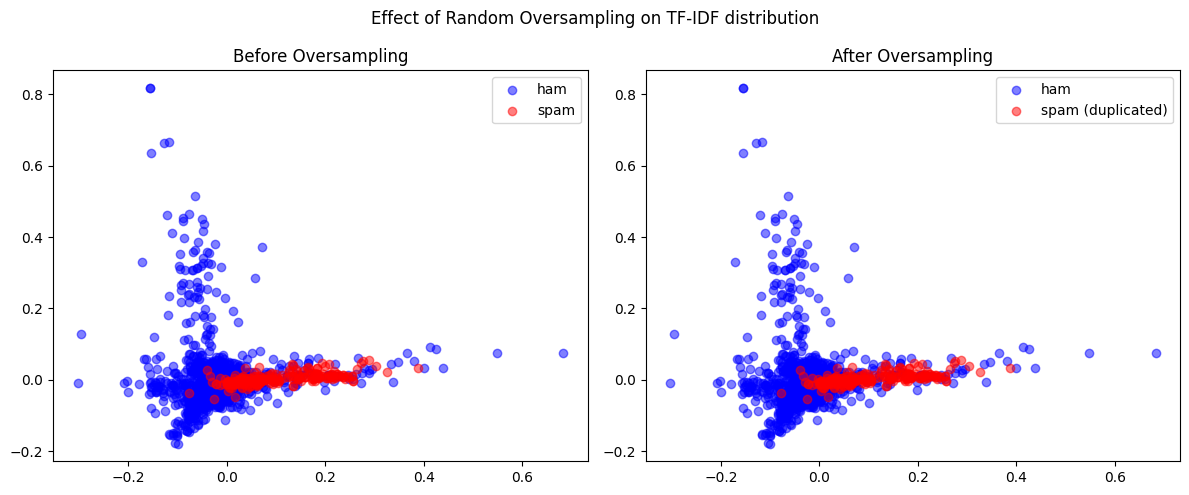


EDA complete - dataset is now balanced without altering ham distribution.


In [27]:
print("\n===== EDA on TF-IDF data after Oversampling =====\n")

# 1. Dataset size before and after
print(f"Training set size BEFORE oversampling: {X_train.shape[0]} (ham: {sum(y_train==0)}, spam: {sum(y_train==1)})")
print(f"Training set size AFTER oversampling:  {X_train_bal.shape[0]} (ham: {sum(y_train_bal==0)}, spam: {sum(y_train_bal==1)})")
print(f"New balance ratio (ham/spam): {sum(y_train_bal==0)/sum(y_train_bal==1):.2f}:1")

# 2. Mean TF-IDF value per class (before vs after)
mean_ham_before = X_train[y_train==0].mean(axis=0).mean()
mean_spam_before = X_train[y_train==1].mean(axis=0).mean()
mean_ham_after = X_train_bal[y_train_bal==0].mean(axis=0).mean()
mean_spam_after = X_train_bal[y_train_bal==1].mean(axis=0).mean()

print(f"\nMean TF-IDF (ham)  before: {mean_ham_before:.6f}   after: {mean_ham_after:.6f}")
print(f"Mean TF-IDF (spam) before: {mean_spam_before:.6f}   after: {mean_spam_after:.6f}")

# 3. PCA visualization to compare distribution
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2, random_state=42)
X_pca_before = pca.fit_transform(X_train[:2000])
y_before = y_train[:2000]

X_pca_after = pca.transform(X_train_bal[:2000])
y_after = y_train_bal[:2000]

fig, axes = plt.subplots(1, 2, figsize=(12,5))
axes[0].scatter(X_pca_before[y_before==0,0], X_pca_before[y_before==0,1], c='blue', label='ham', alpha=0.5)
axes[0].scatter(X_pca_before[y_before==1,0], X_pca_before[y_before==1,1], c='red', label='spam', alpha=0.5)
axes[0].set_title("Before Oversampling")
axes[0].legend()

axes[1].scatter(X_pca_after[y_after==0,0], X_pca_after[y_after==0,1], c='blue', label='ham', alpha=0.5)
axes[1].scatter(X_pca_after[y_after==1,0], X_pca_after[y_after==1,1], c='red', label='spam (duplicated)', alpha=0.5)
axes[1].set_title("After Oversampling")
axes[1].legend()
plt.suptitle("Effect of Random Oversampling on TF-IDF distribution")
plt.tight_layout()
plt.show()

print("\nEDA complete - dataset is now balanced without altering ham distribution.")

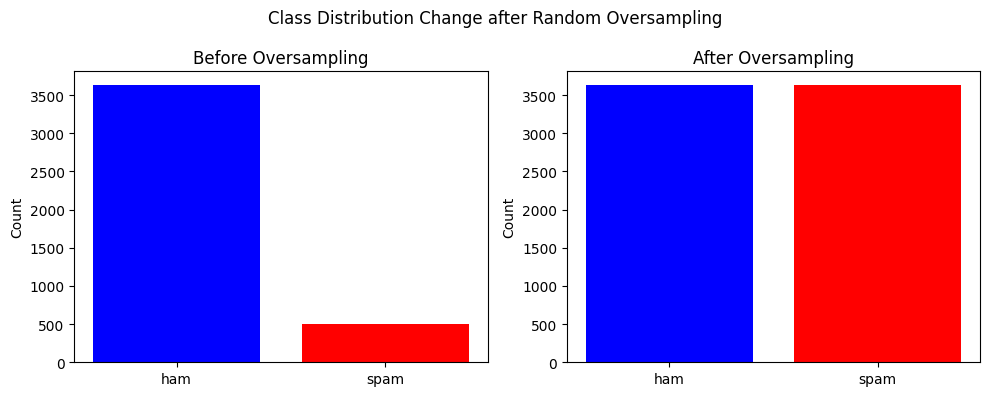

In [28]:
# Class distribution comparison
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].bar(['ham', 'spam'], [sum(y_train==0), sum(y_train==1)], color=['blue', 'red'])
axes[0].set_title('Before Oversampling')
axes[0].set_ylabel('Count')

axes[1].bar(['ham', 'spam'], [sum(y_train_bal==0), sum(y_train_bal==1)], color=['blue', 'red'])
axes[1].set_title('After Oversampling')
axes[1].set_ylabel('Count')

plt.suptitle('Class Distribution Change after Random Oversampling')
plt.tight_layout()
plt.show()

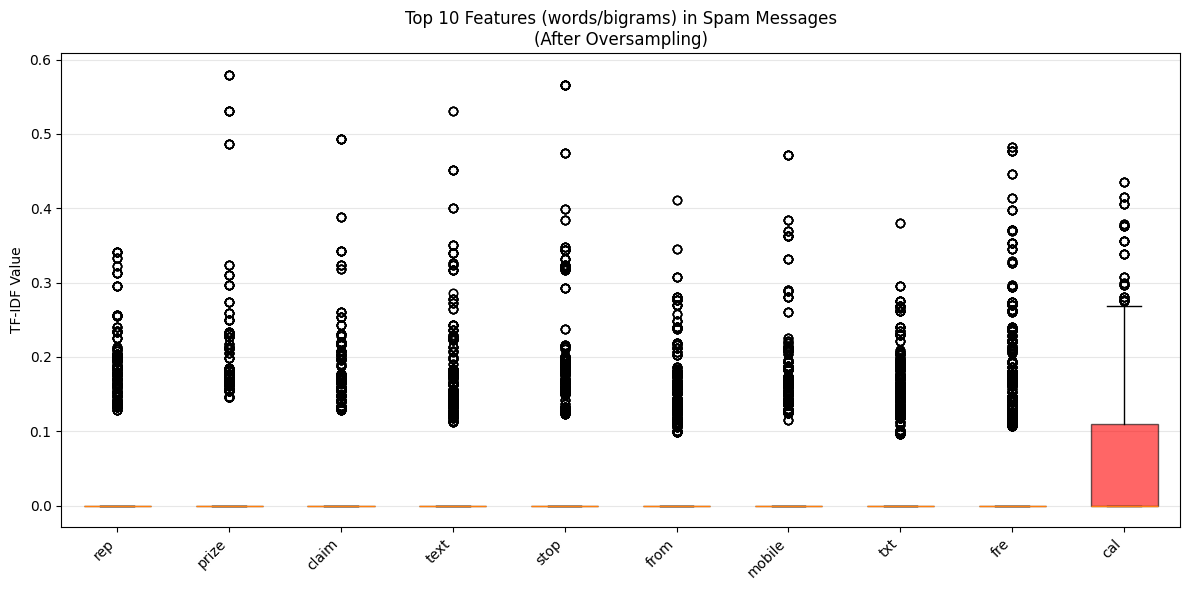

In [29]:
# Get top 10 features with highest mean TF-IDF in spam (after oversampling)
feature_means_spam = X_train_bal[y_train_bal==1].mean(axis=0)
top10_idx = np.argsort(feature_means_spam)[-10:]

feature_names = [list(vocab.keys())[list(vocab.values()).index(i)] for i in top10_idx]

# Extract values for those features
spam_vals = X_train_bal[y_train_bal==1][:, top10_idx]
ham_vals = X_train_bal[y_train_bal==0][:, top10_idx]

plt.figure(figsize=(12, 6))
plt.boxplot([spam_vals[:, i] for i in range(10)], positions=range(10), widths=0.6, patch_artist=True,
            boxprops=dict(facecolor='red', alpha=0.6), labels=feature_names)
plt.xticks(rotation=45, ha='right')
plt.title('Top 10 Features (words/bigrams) in Spam Messages\n(After Oversampling)')
plt.ylabel('TF-IDF Value')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

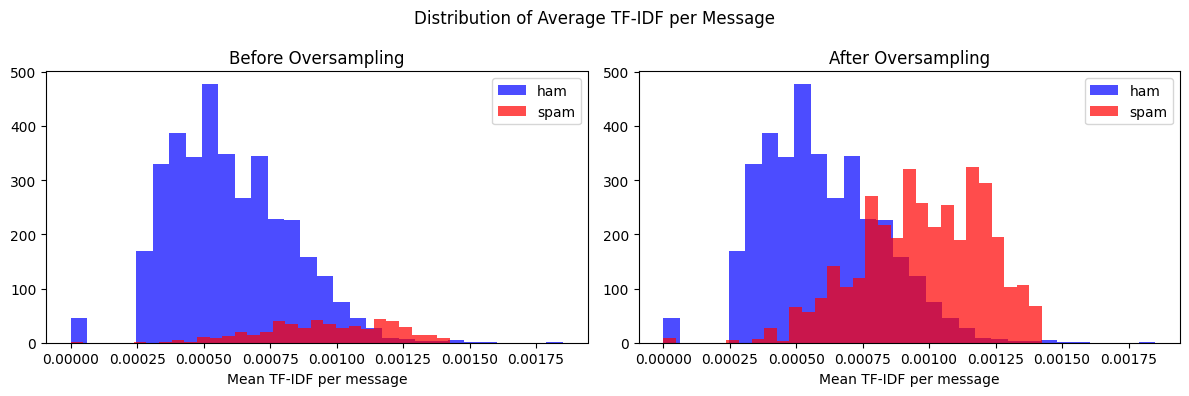

In [30]:
# Mean TF-IDF per sample (average over all features)
mean_per_sample_before = X_train.mean(axis=1)
mean_per_sample_after = X_train_bal.mean(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(mean_per_sample_before[y_train==0], bins=30, alpha=0.7, label='ham', color='blue')
axes[0].hist(mean_per_sample_before[y_train==1], bins=30, alpha=0.7, label='spam', color='red')
axes[0].set_title('Before Oversampling')
axes[0].set_xlabel('Mean TF-IDF per message')
axes[0].legend()

axes[1].hist(mean_per_sample_after[y_train_bal==0], bins=30, alpha=0.7, label='ham', color='blue')
axes[1].hist(mean_per_sample_after[y_train_bal==1], bins=30, alpha=0.7, label='spam', color='red')
axes[1].set_title('After Oversampling')
axes[1].set_xlabel('Mean TF-IDF per message')
axes[1].legend()

plt.suptitle('Distribution of Average TF-IDF per Message')
plt.tight_layout()
plt.show()

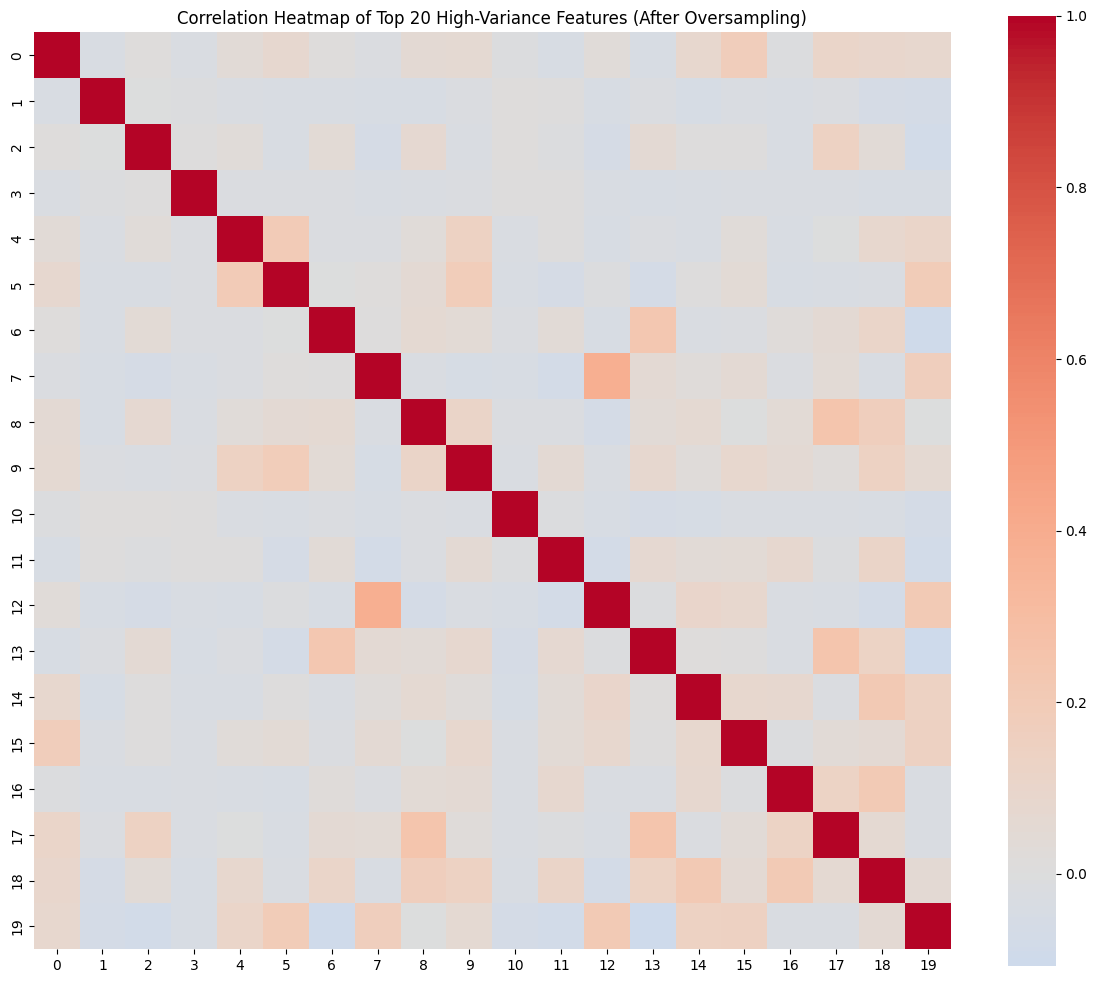

In [31]:
import seaborn as sns

# Get top 20 features by variance
variances = X_train_bal.var(axis=0)
top20_idx = np.argsort(variances)[-20:]
X_top20 = X_train_bal[:, top20_idx]

# Correlation matrix
corr = np.corrcoef(X_top20.T)

plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=False, cmap='coolwarm', center=0, square=True)
plt.title('Correlation Heatmap of Top 20 High-Variance Features (After Oversampling)')
plt.tight_layout()
plt.show()

****Multinomial Naive Bayes****


In [32]:
class MultinomialNB:
    def fit(self, X, y):
        self.classes = [0,1]
        self.prior = {}
        self.cond_prob = {}
        X = np.array(X)
        y = np.array(y)
        n_features = X.shape[1]
        for c in self.classes:
            X_c = X[y == c]
            self.prior[c] = len(X_c) / len(X)
            total_feat = np.sum(X_c, axis=0)
            total_sum = np.sum(total_feat)
             
            self.cond_prob[c] = (total_feat + 1) / (total_sum + n_features)
    
    def predict(self, X):
        X = np.array(X)
        preds = []
        for x in X:
            scores = {}
            for c in self.classes:
                score = math.log(self.prior[c])
                for j in range(len(x)):
                    if x[j] > 0:
                         
                        prob = max(self.cond_prob[c][j], 1e-10)
                        score += x[j] * math.log(prob)
                scores[c] = score
            preds.append(max(scores, key=scores.get))
        return preds

mnb = MultinomialNB()
mnb.fit(X_train_bal, y_train_bal)
pred_mnb = mnb.predict(X_test)
acc_mnb, prec_mnb, rec_mnb, f1_mnb, tp_mnb, tn_mnb, fp_mnb, fn_mnb = compute_metrics(y_test, pred_mnb)

print("\n Multinomial Naive Bayes")
print("="*50)
print_full_report(y_test, pred_mnb, ['Ham', 'Spam'])


 Multinomial Naive Bayes
             precision    recall  f1-score   support
         Ham     0.968     0.985     0.977       887
        Spam     0.827     0.912     0.867       147

Accuracy: 0.9603
Confusion Matrix:
          Predicted
          Ham   Spam
Actual Ham  859    28
       Spam  13   134


****Bernoulli Naive Bayes****

In [33]:
 
class BernoulliNB:
    def __init__(self, alpha=1.0, spam_weight=3.0, threshold_shift=3):
        self.alpha = alpha
        self.spam_weight = spam_weight
        self.threshold_shift = threshold_shift

    def fit(self, X, y):
        self.classes = list(set(y))
        self.prior = {}
        self.prob = {}
        for c in self.classes:
            X_c = [X[i] for i in range(len(X)) if y[i] == c]
            prior = len(X_c) / len(X)
            if c == 1:
                prior *= self.spam_weight
            self.prior[c] = prior
            counts = [0] * len(X[0])
            for row in X_c:
                for j in range(len(row)):
                    if row[j] > 0:
                        counts[j] += 1
            self.prob[c] = [
                (counts[j] + self.alpha) / (len(X_c) + 2 * self.alpha)
                for j in range(len(counts))
            ]

    def predict(self, X):
        preds = []
        for x in X:
            scores = {}
            for c in self.classes:
                score = math.log(self.prior[c])
                for j in range(len(x)):
                    p = self.prob[c][j]
                    if x[j] > 0:
                        score += math.log(p + 1e-9)
                    else:
                        score += math.log(1 - p + 1e-9)
                scores[c] = score
            if scores[1] > scores[0] - self.threshold_shift:
                preds.append(1)
            else:
                preds.append(0)
        return preds

bnb = BernoulliNB(alpha=1.0, spam_weight=3.0, threshold_shift=3)
bnb.fit(X_train_bal, y_train_bal)
pred_bnb = bnb.predict(X_test)

acc_bnb, prec_bnb, rec_bnb, f1_bnb, tp_bnb, tn_bnb, fp_bnb, fn_bnb = compute_metrics(y_test, pred_bnb)

print("\n Bernoulli NB ")
print("="*50)
print_full_report(y_test, pred_bnb, ['Ham', 'Spam'])


 Bernoulli NB 
             precision    recall  f1-score   support
         Ham     0.992     0.982     0.987       887
        Spam     0.949     0.891     0.919       147

Accuracy: 0.9778
Confusion Matrix:
          Predicted
          Ham   Spam
Actual Ham  880     7
       Spam  16   131


****Standard Scaling****

In [34]:
def standard_scaler(X):
    X = np.array(X)
    mean = np.mean(X, axis=0)
    std = np.std(X, axis=0)
    std[std == 0] = 1
    X_scaled = (X - mean) / std
    return X_scaled, mean, std

X_train_scaled, mean_vals, std_vals = standard_scaler(X_train_bal)
X_test_scaled = (X_test - mean_vals) / std_vals

****Logistic Regression****

In [35]:
class LogisticRegression:
    def __init__(self, lr=0.01, epochs=200):
        self.lr = lr
        self.epochs = epochs
    
    def sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -250, 250)))
    
    def fit(self, X, y):
        X = np.array(X)
        y = np.array(y)
        self.weights = np.zeros(X.shape[1])
        self.bias = 0
        for _ in range(self.epochs):
            linear = np.dot(X, self.weights) + self.bias
            pred = self.sigmoid(linear)
            dw = np.dot(X.T, (pred - y)) / len(y)
            db = np.sum(pred - y) / len(y)
            self.weights -= self.lr * dw
            self.bias -= self.lr * db
    
    def predict(self, X):
        linear = np.dot(np.array(X), self.weights) + self.bias
        return (self.sigmoid(linear) >= 0.5).astype(int)

lr = LogisticRegression(lr=0.1, epochs=200)
lr.fit(X_train_scaled, y_train_bal)
pred_lr = lr.predict(X_test_scaled)
acc_lr, prec_lr, rec_lr, f1_lr, tp_lr, tn_lr, fp_lr, fn_lr = compute_metrics(y_test, pred_lr)

print("\n Logistic Regression")
print("="*50)
print_full_report(y_test, pred_lr, ['Ham', 'Spam'])


 Logistic Regression
             precision    recall  f1-score   support
         Ham     0.986     0.982     0.984       887
        Spam     0.916     0.891     0.903       147

Accuracy: 0.9729
Confusion Matrix:
          Predicted
          Ham   Spam
Actual Ham  875    12
       Spam  16   131


****Perceptron****

In [36]:
class Perceptron:
    def __init__(self, lr=0.01, epochs=500):
        self.lr = lr
        self.epochs = epochs
    
    def fit(self, X, y):
        X = np.array(X)
        y = np.array(y)
        self.weights = np.zeros(X.shape[1])
        self.bias = 0
        for _ in range(self.epochs):
            errors = 0
            for i, x_i in enumerate(X):
                linear = np.dot(x_i, self.weights) + self.bias
                y_pred = 1 if linear >= 0 else 0
                if y_pred != y[i]:
                    self.weights += self.lr * (y[i] - y_pred) * x_i
                    self.bias += self.lr * (y[i] - y_pred)
                    errors += 1
            if errors == 0:
                break
    
    def predict(self, X):
        linear = np.dot(np.array(X), self.weights) + self.bias
        return (linear >= 0).astype(int)

perc = Perceptron(lr=0.01, epochs=500)
perc.fit(X_train_scaled, y_train_bal)
pred_perc = perc.predict(X_test_scaled)
acc_perc, prec_perc, rec_perc, f1_perc, tp_perc, tn_perc, fp_perc, fn_perc = compute_metrics(y_test, pred_perc)

print("\n Perceptron ")
print("="*50)
print_full_report(y_test, pred_perc, ['Ham', 'Spam'])


 Perceptron 
             precision    recall  f1-score   support
         Ham     0.918     0.967     0.942       887
        Spam     0.620     0.810     0.702       147

Accuracy: 0.9023
Confusion Matrix:
          Predicted
          Ham   Spam
Actual Ham  814    73
       Spam  28   119


****EnsembleVoting****

In [37]:
 
 
bnb_full = BernoulliNB(alpha=1.0, spam_weight=3.0, threshold_shift=3)
bnb_full.fit(X_train_scaled, y_train_bal)    

 
class EnsembleVoting:
    def __init__(self, models, weights=None):
        self.models = models
        self.weights = weights if weights else [1.0] * len(models)
        total = sum(self.weights)
        self.weights = [w / total for w in self.weights]
    
    def predict(self, X):
        X = np.array(X)
        n_samples = X.shape[0]
        n_models = len(self.models)
        all_preds = np.zeros((n_models, n_samples), dtype=int)
        for i, (_, model) in enumerate(self.models):
            pred = model.predict(X)
            all_preds[i] = pred
        final_preds = []
        for j in range(n_samples):
            vote_counts = {0: 0.0, 1: 0.0}
            for i in range(n_models):
                pred = all_preds[i, j]
                vote_counts[pred] += self.weights[i]
            final_preds.append(1 if vote_counts[1] > vote_counts[0] else 0)
        return final_preds

 
ensemble = EnsembleVoting(
    models=[
        ('bnb', bnb_full),            
        ('logreg', lr),                
        ('perceptron', perc)           
    ],
    weights=[1.2, 1.0, 0.8]            
)

 
pred_ensemble = ensemble.predict(X_test_scaled)
acc_ens, prec_ens, rec_ens, f1_ens, tp_ens, tn_ens, fp_ens, fn_ens = compute_metrics(y_test, pred_ensemble)

print("\n Ensemble Voting")
print("="*50)
print_full_report(y_test, pred_ensemble, ['Ham', 'Spam'])


 Ensemble Voting
             precision    recall  f1-score   support
         Ham     0.988     0.982     0.985       887
        Spam     0.923     0.891     0.907       147

Accuracy: 0.9739
Confusion Matrix:
          Predicted
          Ham   Spam
Actual Ham  876    11
       Spam  16   131


****Models Comparison****

In [38]:
print("\n" + "="*70)
print("Model Comparison")
print("="*70)
print(f"{'Model':<25} {'Accuracy':<10} {'Precision':<12} {'Recall':<10} {'F1':<10}")
print("-"*70)
print(f"{'Multinomial NB':<25}{acc_mnb:<10.4f} {prec_mnb:<12.4f} {rec_mnb:<10.4f} {f1_mnb:<10.4f}")
print(f"{'Bernoulli NB':<25}{acc_bnb:<10.4f} {prec_bnb:<12.4f} {rec_bnb:<10.4f} {f1_bnb:<10.4f}")
print(f"{'Logistic Reg':<25}{acc_lr:<10.4f} {prec_lr:<12.4f} {rec_lr:<10.4f} {f1_lr:<10.4f}")
print(f"{'Perceptron':<25}{acc_perc:<10.4f} {prec_perc:<12.4f} {rec_perc:<10.4f} {f1_perc:<10.4f}")
print(f"{'Ensemble Voting':<25}{acc_ens:<10.4f} {prec_ens:<12.4f} {rec_ens:<10.4f} {f1_ens:<10.4f}")

best_f1 = max([(f1_mnb, 'Multinomial NB'), (f1_bnb, 'Bernoulli NB'), 
               (f1_lr, 'Logistic Reg'), (f1_perc, 'Perceptron'),
               (f1_ens, 'Ensemble Voting')])
print("\n" + "="*70)
print(f"Best Model based on Spam F1-Score: {best_f1[1]} with F1 = {best_f1[0]:.4f}")


Model Comparison
Model                     Accuracy   Precision    Recall     F1        
----------------------------------------------------------------------
Multinomial NB           0.9603     0.8272       0.9116     0.8673    
Bernoulli NB             0.9778     0.9493       0.8912     0.9193    
Logistic Reg             0.9729     0.9161       0.8912     0.9034    
Perceptron               0.9023     0.6198       0.8095     0.7021    
Ensemble Voting          0.9739     0.9225       0.8912     0.9066    

Best Model based on Spam F1-Score: Bernoulli NB with F1 = 0.9193


****Save Trained Models****

In [39]:
import pickle

models_to_save = {
    'mnb_model.pkl': mnb,
    'bnb_model.pkl': bnb,
    'lr_model.pkl': lr,
    'perceptron_model.pkl': perc,
    'ensemble_model.pkl': ensemble
}

for filename, model_obj in models_to_save.items():
    with open(filename, 'wb') as f:
        pickle.dump(model_obj, f)

preprocessing_objects = {
    'vocab': vocab,
    'idf': idf,
    'mean_vals': mean_vals,
    'std_vals': std_vals,
    'max_features': MAX_FEATURES,
    'stopwords': stopwords,
    'top_features': top_features if 'top_features' in dir() else None
}
with open('preprocessing.pkl', 'wb') as f:
    pickle.dump(preprocessing_objects, f)

print("All files saved successfully!")

All files saved successfully!
